<a href="https://colab.research.google.com/github/Mell03y/Mell03y/blob/main/Fashion_MNIST_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import keras
from keras import layers
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [2]:
#https://keras.io/api/datasets/fashion_mnist/

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
print("x_train şekli:", x_train.shape)
print("y_train şekli:", y_train.shape)
print("x_test şekli:", x_test.shape)
print("y_test şekli:", y_test.shape)

x_train şekli: (60000, 28, 28)
y_train şekli: (60000,)
x_test şekli: (10000, 28, 28)
y_test şekli: (10000,)


In [4]:
sinif_adlari = ["Tişört/Üst", "Pantalon", "Kazak", "Elbise", "Mont", "Sandalet", "Gömlek", "Spor Ayakkabı", "Çanta", "Bot"]

print("İlk 10 Etiket:", y_train[:10])
print("İlk ürün:", sinif_adlari[y_train[0]])
print("İlk ürün:", sinif_adlari[y_train[1]])

İlk 10 Etiket: [9 0 0 3 0 2 7 2 5 5]
İlk ürün: Bot
İlk ürün: Tişört/Üst


In [5]:
print("veri tipi:", x_train.dtype)
print("En küçük piksel:", x_train.min()) # en küçük değer ve en büyük değer. teoride pixelin 0 - 255 arasında olduğunu görmüştük. İspatladık
print("En büyük piksel:", x_train.max())
print(x_train[0][10:24,4:18]) # Bir parça seçip nasıl göründüğüne baktık.

veri tipi: uint8
En küçük piksel: 0
En büyük piksel: 255
[[  0   0   0   0   0   0   0   0   0 193 228 218 213 198]
 [  0   0   0   0   0   1   3   0  12 219 220 212 218 192]
 [  0   0   0   0   0   0   6   0  99 244 222 220 218 203]
 [  0   0   0   0   0   4   0   0  55 236 228 230 228 240]
 [  6   7   2   0   0   0   0   0 237 226 217 223 222 219]
 [  0   0   0   0   0  62 145 204 228 207 213 221 218 208]
 [ 18  44  82 107 189 228 220 222 217 226 200 205 211 230]
 [224 221 224 208 204 214 208 209 200 159 245 193 206 223]
 [221 211 211 214 205 205 205 220 240  80 150 255 229 221]
 [222 229 229 234 249 220 194 215 217 241  65  73 106 117]
 [193 205 211 225 216 185 197 206 198 213 240 195 227 245]
 [213 197 185 190 194 192 202 214 219 221 220 236 225 216]
 [179 171 183 196 204 210 213 207 211 210 200 196 194 191]
 [212 191 175 172 175 181 185 188 189 188 193 198 204 209]]


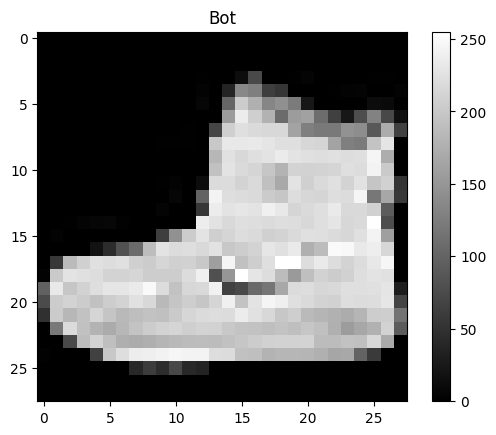

In [6]:
plt.imshow(x_train[0],cmap="gray")
plt.colorbar()
plt.title(sinif_adlari[y_train[0]])
plt.show()

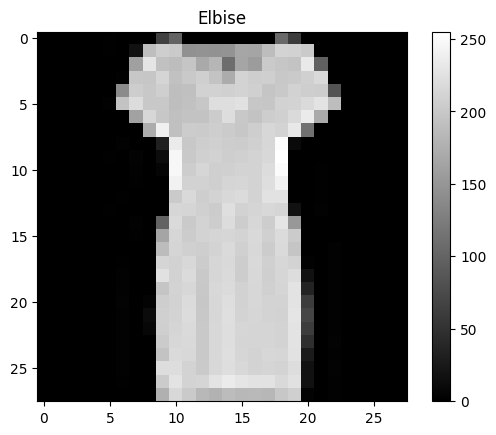

In [7]:
plt.imshow(x_train[20],cmap="gray")
plt.colorbar()
plt.title(sinif_adlari[y_train[20]])
plt.show()

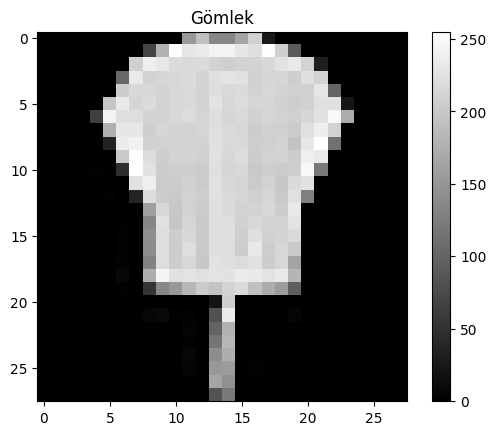

In [8]:

plt.imshow(x_train[56],cmap="gray")
plt.colorbar()
plt.title(sinif_adlari[y_train[56]])
plt.show()

In [9]:
print("Eğitim verisinde her sınıfta kaç resim var?")
print(np.bincount(y_train)) # 0 dan 9 a kadar her sayının kaç kez geçtiğini sayar.
print("Test verisinde her sınıfta kaç resim var?")
print(np.bincount(y_test))

Eğitim verisinde her sınıfta kaç resim var?
[6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]
Test verisinde her sınıfta kaç resim var?
[1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [10]:
x_train = x_train / 255.0
x_test = x_test / 255.0

print("En küçük değer:", x_train.min())
print("En büyük değer:", x_train.max())


En küçük değer: 0.0
En büyük değer: 1.0


In [11]:
keras.utils.set_random_seed(42)

dense_model = keras.Sequential([
    keras.Input(shape=(28,28)), # datamın modele her seferinde 28*28 lik bir resim geleceğini söylüyorum.
    layers.Flatten(), #teori notunda konuştuğumuz gibi datayı ağa 28*28 değil tekbir 784 sayılık tek bir satır olarak veriyor.
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax") # çoklu sınıflandırma yaptımız için softmax kullandık. 2 li olsaydı. sigmoid olaurdu.
])

dense_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
dense_model.compile(
    optimizer="adam", # learning rate, varsayılan değer olsun.
    loss="sparse_categorical_crossentropy", # loss fonksiyonu. Çoklu sınıflandırma için kayıp fonksiyonu. Model doğru sınıfa verdiği olasılık düştükçe daha çok ceza alır.
    metrics=["accuracy"] # Doğru tahmin oranını raporlar.
)

In [13]:
dense_gecmis = dense_model.fit(x_train, y_train,
                               epochs=10,
                               batch_size=32,
                               validation_split=0.2 # eğitim datasının içinden %20 sini doğrulama için ayıracak.
                               )

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8186 - loss: 0.5173 - val_accuracy: 0.8438 - val_loss: 0.4392
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.8614 - loss: 0.3881 - val_accuracy: 0.8547 - val_loss: 0.4019
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8753 - loss: 0.3454 - val_accuracy: 0.8662 - val_loss: 0.3702
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8846 - loss: 0.3176 - val_accuracy: 0.8772 - val_loss: 0.3495
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8920 - loss: 0.2975 - val_accuracy: 0.8783 - val_loss: 0.3496
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8972 - loss: 0.2816 - val_accuracy: 0.8816 - val_loss: 0.3409
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9019 - loss: 0.2677 - val_accuracy: 0.8810 - val_loss: 0.3466
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9047 - loss: 0.256

In [14]:
dense_kayip, dense_doğruluk = dense_model.evaluate(x_test, y_test)

print("Test Kaybı:", dense_kayip)
print("Test Doğruluğu:", dense_doğruluk)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8708 - loss: 0.3770
Test Kaybı: 0.37695103883743286
Test Doğruluğu: 0.8708000183105469


In [15]:

olasiliklar = dense_model.predict(x_test)
print("Tahmin Tablosu:", olasiliklar.shape)
print(np.round(olasiliklar[0],3))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Tahmin Tablosu: (10000, 10)
[0.    0.    0.    0.    0.    0.001 0.    0.045 0.    0.954]


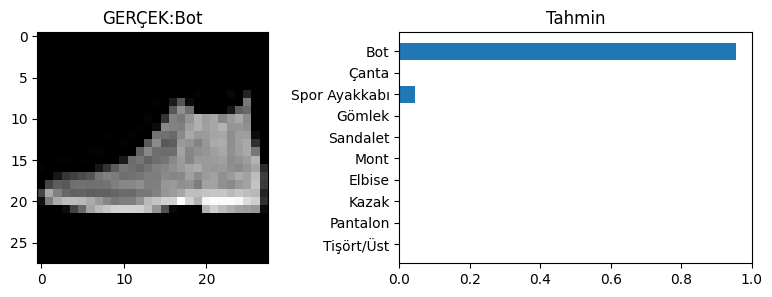

In [16]:
plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.imshow(x_test[0],cmap="gray")
plt.title("GERÇEK:"+ sinif_adlari[np.argmax(olasiliklar[0])])
plt.subplot(1,2,2)
plt.barh(sinif_adlari, olasiliklar[0])
plt.title("Tahmin")
plt.xlim(0,1)

plt.show()

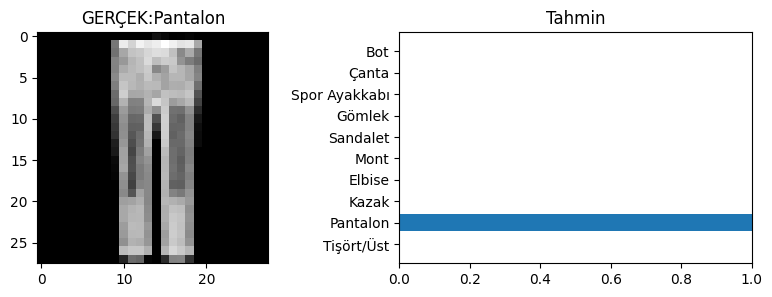

In [17]:
plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.imshow(x_test[15],cmap="gray")
plt.title("GERÇEK:"+ sinif_adlari[np.argmax(olasiliklar[15])])
plt.subplot(1,2,2)
plt.barh(sinif_adlari, olasiliklar[15])
plt.title("Tahmin")
plt.xlim(0,1)

plt.show()

In [18]:

print(classification_report(y_test, np.argmax(olasiliklar, axis=1)))

              precision    recall  f1-score   support

           0       0.87      0.77      0.81      1000
           1       0.99      0.96      0.98      1000
           2       0.82      0.75      0.78      1000
           3       0.86      0.90      0.88      1000
           4       0.78      0.80      0.79      1000
           5       0.98      0.95      0.97      1000
           6       0.65      0.72      0.69      1000
           7       0.89      0.99      0.93      1000
           8       0.91      0.98      0.94      1000
           9       0.98      0.90      0.94      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



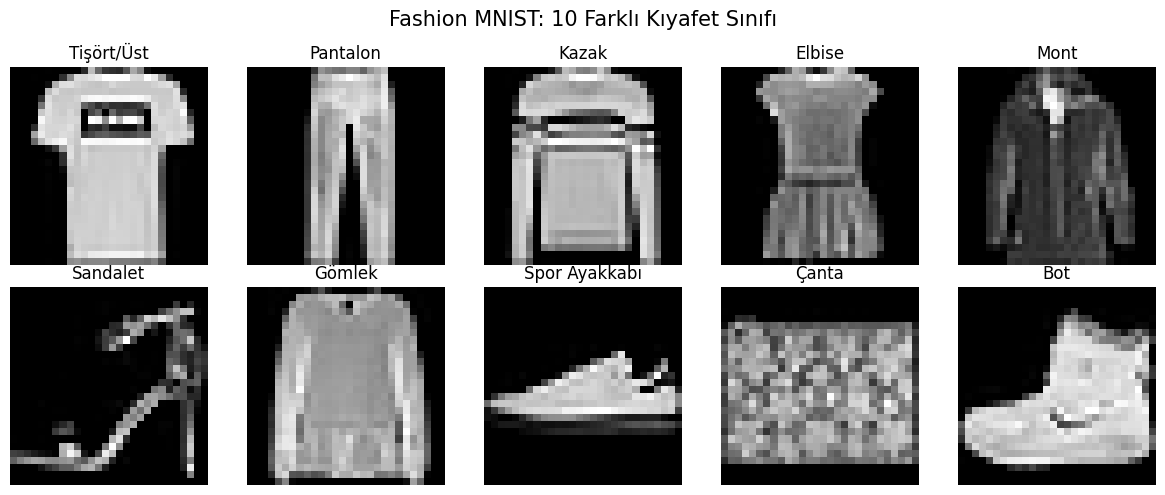

In [19]:
plt.figure(figsize=(12, 5))

for sinif in range(10):
    indeks = np.where(y_train == sinif)[0][0]

    plt.subplot(2, 5, sinif + 1)
    plt.imshow(x_train[indeks], cmap="gray")
    plt.title(sinif_adlari[sinif])
    plt.axis("off")

plt.suptitle("Fashion MNIST: 10 Farklı Kıyafet Sınıfı", fontsize=15)
plt.tight_layout()
plt.show()

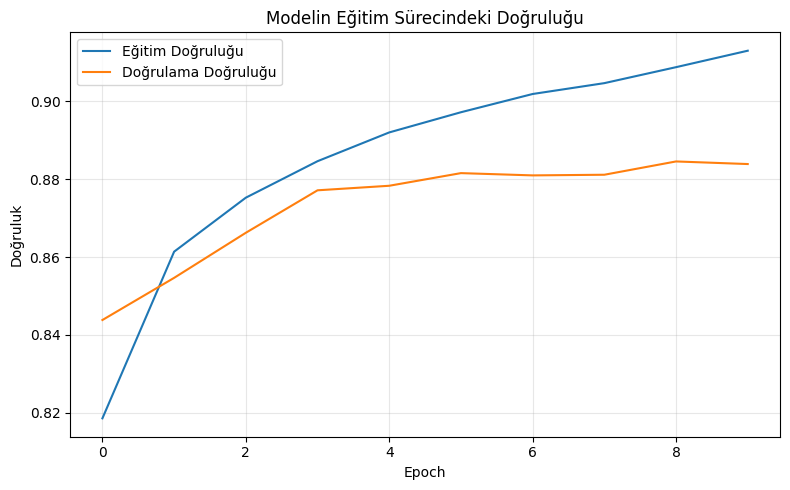

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    dense_gecmis.history["accuracy"],
    label="Eğitim Doğruluğu"
)

plt.plot(
    dense_gecmis.history["val_accuracy"],
    label="Doğrulama Doğruluğu"
)

plt.title("Modelin Eğitim Sürecindeki Doğruluğu")
plt.xlabel("Epoch")
plt.ylabel("Doğruluk")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

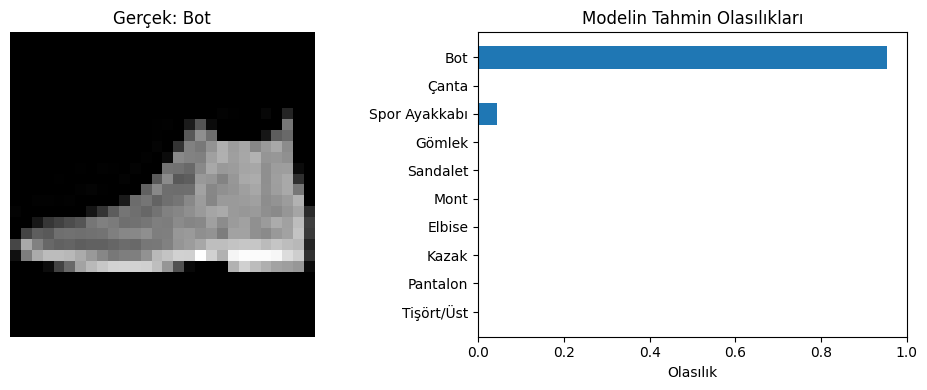

Modelin tahmini: Bot
Gerçek sınıf: Bot


In [21]:
indeks = 0

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(x_test[indeks], cmap="gray")
plt.title("Gerçek: " + sinif_adlari[y_test[indeks]])
plt.axis("off")

plt.subplot(1, 2, 2)
plt.barh(sinif_adlari, olasiliklar[indeks])
plt.title("Modelin Tahmin Olasılıkları")
plt.xlabel("Olasılık")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

print("Modelin tahmini:", sinif_adlari[np.argmax(olasiliklar[indeks])])
print("Gerçek sınıf:", sinif_adlari[y_test[indeks]])